# 🇵🇰 Pakistan Census 2017: Population Analysis (1998 → 2017)
### Data Analytics project with Python (pandas, matplotlib, seaborn)

---
## 1. Problem Statement
Pakistan's population grew a lot between the **1998** and **2017** censuses. Planners, policymakers and businesses need simple answers to questions like these:

| # | Question |
|---|---|
| Q1 | How many people live in each province, and how fast did each province grow? |
| Q2 | How much of Pakistan is **urban (cities)** vs **rural (villages)**, and is that changing? |
| Q3 | Which districts are the biggest, the most crowded (density), and the fastest growing? |
| Q4 | What do the **sex ratio** and **household size** tell us? |
| Q5 | Is population spread evenly, or concentrated in a few districts? |

### Dataset: `Population-Dataset.csv`
One row = one **sub-division (tehsil)**, 528 rows. Every number is given separately for **RURAL** and **URBAN** areas.

| Column | Meaning |
|---|---|
| PROVINCE, DIVISION, DISTRICT, SUB DIVISION | Location (4 levels) |
| AREA (sq.km) | Land area |
| ALL SEXES / MALE / FEMALE / TRANSGENDER | Population in 2017 |
| SEX RATIO | **Males per 100 females** (above 100 = more men) |
| AVG HOUSEHOLD SIZE | Average people per household |
| POPULATION 1998 | Population in the 1998 census |
| ANNUAL GROWTH RATE | Yearly growth % between 1998 and 2017 |

> ℹ️ Islamabad (ICT) is **not** in this file, so totals are a little lower than the official national figure.

## 2. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# One simple, consistent style for all charts
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "grid.color": "#e6e6e3"})

# Show big numbers as 1.2M / 450K instead of 1e8
def human(x, _=None):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:.0f}"
HUMAN = mtick.FuncFormatter(human)

## 3. Load & First Look

In [2]:
df = pd.read_csv("Population-Dataset.csv")
df.columns = df.columns.str.strip().str.upper()
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (528, 21)


,PROVINCE,DIVISION,DISTRICT,SUB DIVISION,AREA (SQ.KM),ALL SEXES (RURAL),MALE (RURAL),FEMALE (RURAL),TRANSGENDER (RURAL),SEX RATIO (RURAL),...,POPULATION 1998 (RURAL),ANNUAL GROWTH RATE (RURAL),ALL SEXES (URBAN),MALE (URBAN),FEMALE (URBAN),TRANSGENDER (URBAN),SEX RATIO (URBAN),AVG HOUSEHOLD SIZE (URBAN),POPULATION 1998 (URBAN),ANNUAL GROWTH RATE (URBAN)
0,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,BAHAWALNAGAR TEHSIL,1729.0,619550,316864,302644,42,104.70,...,407768,2.22,193840,98391,95402,47,103.13,6.02,133785,1.97
1,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,CHISHTIAN TEHSIL,1500.0,540342,273788,266500,54,102.73,...,395983,1.65,149424,75546,73851,27,102.30,6.01,102287,2.01
2,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,FORT ABBAS TEHSIL,2536.0,361240,182655,178541,44,102.30,...,250959,1.93,61528,31360,30150,18,104.01,6.00,34637,3.06
3,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,HAROONABAD TEHSIL,1295.0,382115,192278,189808,29,101.30,...,297343,1.33,142600,71345,71236,19,100.15,6.02,84424,2.79
4,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,MINCHINABAD TEHSIL,1818.0,452723,231506,221178,39,104.67,...,316593,1.90,72294,36694,35590,10,103.10,6.34,37668,3.48


In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
AREA (SQ.KM),528.0,1492.0,2039.5,0.0,425.0,882.0,1734.2,18374.0
ALL SEXES (RURAL),528.0,246278.0,271189.8,0.0,50934.5,165241.0,312911.2,2297375.0
MALE (RURAL),528.0,125275.7,137563.0,0.0,27127.2,84134.5,160502.2,1172995.0
FEMALE (RURAL),528.0,120984.1,133716.9,0.0,23979.0,82044.0,152219.0,1124167.0
TRANSGENDER (RURAL),528.0,18.2,25.5,0.0,1.0,10.0,25.0,213.0
SEX RATIO (RURAL),528.0,99.0,26.8,0.0,101.1,105.3,108.3,139.4
AVG HOUSEHOLD SIZE (RURAL),528.0,6.3,2.1,0.0,5.7,6.3,7.2,12.4
POPULATION 1998 (RURAL),528.0,167428.0,178389.0,0.0,35273.5,117206.5,213054.2,1044035.0
ANNUAL GROWTH RATE (RURAL),528.0,3.1,9.6,0.0,1.4,2.0,2.8,100.0
ALL SEXES (URBAN),528.0,140863.5,351246.3,0.0,0.0,43254.5,117814.8,3653616.0


**What we see:** 
- **528 tehsils and 21 columns**, with no missing values. That looks clean, but the next step shows the real problems.
- Tehsil size varies hugely: from **2,665 people up to 4.27 million** (Peshawar).
- `AREA` has a minimum of **0**. Land area can never be 0, so this is a red flag 🚩.

## 4. Data Quality Check (finding the hidden problems)

In [4]:
print("Missing values:", df.isna().sum().sum())
print("\nSub-divisions with AREA = 0:")
print(df.loc[df["AREA (SQ.KM)"] == 0, ["DISTRICT", "SUB DIVISION", "AREA (SQ.KM)"]].to_string())

no_urban = df["ALL SEXES (URBAN)"] == 0
print("\nSub-divisions with NO urban population:", no_urban.sum())
print("  ...but their URBAN sex ratio is stored as:", df.loc[no_urban, "SEX RATIO (URBAN)"].unique())
print("  ...and URBAN household size is stored as:", df.loc[no_urban, "AVG HOUSEHOLD SIZE (URBAN)"].unique())

print("\nDivision names in mixed case:", df.loc[df["DIVISION"].str.contains("[a-z]"), "DIVISION"].unique()[:5], "...")
print("\nProvinces:", df["PROVINCE"].unique())

Missing values: 0

Sub-divisions with AREA = 0:
                     DISTRICT              SUB DIVISION  AREA (SQ.KM)
393  KILLA SAIFULLAH DISTRICT         BADINI SUB-TEHSIL           0.0
394  KILLA SAIFULLAH DISTRICT  KAN MEHTARZAI SUB-TEHSIL           0.0
396  KILLA SAIFULLAH DISTRICT            LOIBAND TEHSIL           0.0
397  KILLA SAIFULLAH DISTRICT        MUSLIM BAGH TEHSIL           0.0

Sub-divisions with NO urban population: 155
  ...but their URBAN sex ratio is stored as: [0.]
  ...and URBAN household size is stored as: [0.]

Division names in mixed case: <StringArray>
[     'Badin Division',  'Hyderabad Division',    'Karachi Division',
    'Larkana Division', 'Mirpurkhas Division']
Length: 5, dtype: str ...

Provinces: <StringArray>
['PUNJAB', 'SINDH', 'BALOCHISTAN', 'KPK', 'KPK/FATA']
Length: 5, dtype: str


**Problems found:**

1. **4 tehsils of Killa Saifullah have AREA = 0.** Dividing population by 0 gives *infinity*, and those tehsils wrongly appear as the "most crowded" places in Pakistan. ➜ Set to unknown (NaN).
2. **155 tehsils have no urban population**, yet their urban sex ratio and household size are stored as **0**. A plain `.mean()` counts these zeros and drags the average down. For example, the urban sex ratio of FATA would come out as 15.6, which is impossible. ➜ Set to NaN.
3. **Mixed spelling**: `LAHORE DIVISION` vs `Karachi Division`. ➜ Convert all to UPPER case.
4. **KPK/FATA** is listed separately. FATA merged into KPK in 2018, so we add a `PROVINCE_2018` column for the current map.
5. **Sex ratio = males per 100 females** (check: 316,864 ÷ 302,644 × 100 = 104.7). It is *not* "females per 1000 males".

### 4.1 Cleaning & new columns

In [5]:
# 1) Area = 0 is impossible -> treat as unknown
df.loc[df["AREA (SQ.KM)"] == 0, "AREA (SQ.KM)"] = np.nan

# 2) Sex ratio / household size = 0 where there is no urban population -> unknown (not zero!)
for col in ["SEX RATIO (URBAN)", "AVG HOUSEHOLD SIZE (URBAN)"]:
    df.loc[df["ALL SEXES (URBAN)"] == 0, col] = np.nan

# 3) Same text style for names
df["DIVISION"] = df["DIVISION"].str.upper().str.strip()

# 4) FATA merged into KPK in 2018 -> keep a column for today's map too
df["PROVINCE_2018"] = df["PROVINCE"].replace({"KPK/FATA": "KPK"})

# 5) New columns
df["POP_2017"] = df["ALL SEXES (RURAL)"] + df["ALL SEXES (URBAN)"]
df["POP_1998"] = df["POPULATION 1998 (RURAL)"] + df["POPULATION 1998 (URBAN)"]
df["URBAN_2017"] = df["ALL SEXES (URBAN)"]
df["URBAN_1998"] = df["POPULATION 1998 (URBAN)"]
df["MALE"] = df["MALE (RURAL)"] + df["MALE (URBAN)"]
df["FEMALE"] = df["FEMALE (RURAL)"] + df["FEMALE (URBAN)"]
df["TRANSGENDER"] = df["TRANSGENDER (RURAL)"] + df["TRANSGENDER (URBAN)"]
# households = people / avg household size (needed to average household size correctly)
df["HH_RURAL"] = df["ALL SEXES (RURAL)"] / df["AVG HOUSEHOLD SIZE (RURAL)"]
df["HH_URBAN"] = (df["ALL SEXES (URBAN)"] / df["AVG HOUSEHOLD SIZE (URBAN)"]).fillna(0)

# Helper: yearly compound growth rate (CAGR) over 19 years
def cagr(new, old, years=19):
    return ((new / old) ** (1 / years) - 1) * 100
print("Clean ✔  |  Total population 2017:", f"{df.POP_2017.sum():,}")

Clean ✔  |  Total population 2017: 204,410,733


> **Golden rule used in this notebook:** never take a simple `.mean()` of rates or ratios (growth %, sex ratio, density) across tehsils.
> A tehsil of 20,000 people would count the same as one with 2 million people. Instead we **add up the totals first, then calculate the ratio**.

### 4.2 Headline numbers

In [6]:
P17, P98 = df.POP_2017.sum(), df.POP_1998.sum()
kpi = pd.Series({
    "Population 1998": f"{P98/1e6:.1f} M",
    "Population 2017": f"{P17/1e6:.1f} M",
    "People added": f"{(P17-P98)/1e6:.1f} M (+{(P17/P98-1):.0%})",
    "Yearly growth (CAGR)": f"{cagr(P17, P98):.2f}% per year",
    "Urban share 1998 → 2017": f"{df.URBAN_1998.sum()/P98:.1%} → {df.URBAN_2017.sum()/P17:.1%}",
    "Sex ratio (males per 100 females)": f"{df.MALE.sum()/df.FEMALE.sum()*100:.1f}",
    "Transgender persons counted": f"{df.TRANSGENDER.sum():,}",
    "Districts / Tehsils": f"{df.DISTRICT.nunique()} / {len(df)}",
})
print(kpi.to_string())

Population 1998                             130.7 M
Population 2017                             204.4 M
People added                          73.7 M (+56%)
Yearly growth (CAGR)                 2.38% per year
Urban share 1998 → 2017               32.4% → 36.4%
Sex ratio (males per 100 females)             104.8
Transgender persons counted                  21,358
Districts / Tehsils                       131 / 528


**Meaning:** 
- Pakistan (without Islamabad) grew from **130.7M to 204.4M people**, which means **73.7M more people in 19 years (+56%)**.
- That is **2.38% growth every year**, one of the highest rates in Asia. At this speed the population doubles in about **30 years**.
- Cities are growing in share, but slowly: **32.4% → 36.4% urban**. About **2 out of 3 Pakistanis still live in rural areas**.
- There are **104.8 men for every 100 women**.

In [7]:
prov = df.groupby("PROVINCE").agg(POP_2017=("POP_2017", "sum"), POP_1998=("POP_1998", "sum"),
                                  URBAN_2017=("URBAN_2017", "sum"), URBAN_1998=("URBAN_1998", "sum"),
                                  RURAL_2017=("ALL SEXES (RURAL)", "sum"), RURAL_1998=("POPULATION 1998 (RURAL)", "sum"),
                                  AREA=("AREA (SQ.KM)", "sum"), MALE=("MALE", "sum"), FEMALE=("FEMALE", "sum"))
prov["SHARE"] = prov.POP_2017 / prov.POP_2017.sum()
prov["CAGR"] = cagr(prov.POP_2017, prov.POP_1998)
prov["URBAN_%_1998"] = prov.URBAN_1998 / prov.POP_1998 * 100
prov["URBAN_%_2017"] = prov.URBAN_2017 / prov.POP_2017 * 100
prov["URBAN_CAGR"] = cagr(prov.URBAN_2017, prov.URBAN_1998)
prov["RURAL_CAGR"] = cagr(prov.RURAL_2017, prov.RURAL_1998)
prov = prov.sort_values("POP_2017", ascending=False)
ORDER = prov.index.tolist()
COLOR = dict(zip(ORDER, PALETTE))           # each province keeps the same colour in every chart

# Helper: horizontal bar chart with one colour per bar and value labels
from matplotlib.patches import Patch
def hbar(ax, names, values, colors, labels, legend=None, loc="lower right"):
    bars = ax.barh(list(names), list(values), color=list(colors), height=.7)
    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)
    ax.invert_yaxis()                       # biggest on top
    if legend:
        ax.legend(handles=[Patch(color=COLOR[p], label=p) for p in legend], frameon=False, loc=loc, fontsize=8)
    return bars
prov[["POP_1998", "POP_2017", "SHARE", "CAGR", "URBAN_%_1998", "URBAN_%_2017"]].style.format(
    {"POP_1998": "{:,.0f}", "POP_2017": "{:,.0f}", "SHARE": "{:.1%}", "CAGR": "{:.2f}%",
     "URBAN_%_1998": "{:.1f}%", "URBAN_%_2017": "{:.1f}%"})

,POP_1998,POP_2017,SHARE,CAGR,URBAN_%_1998,URBAN_%_2017
PROVINCE,,,,,,
PUNJAB,"73,004,786","109,054,593",53.4%,2.13%,31.4%,37.0%
SINDH,"30,429,937","47,844,275",23.4%,2.41%,48.8%,51.9%
KPK,"17,776,387","30,497,911",14.9%,2.88%,16.3%,18.4%
BALOCHISTAN,"6,539,503","12,286,335",6.0%,3.37%,24.0%,27.7%
KPK/FATA,"2,967,699","4,727,619",2.3%,2.48%,2.9%,3.0%


---
## 5. Province Level (Q1)
### Plot 1 · Bar chart: Population by province

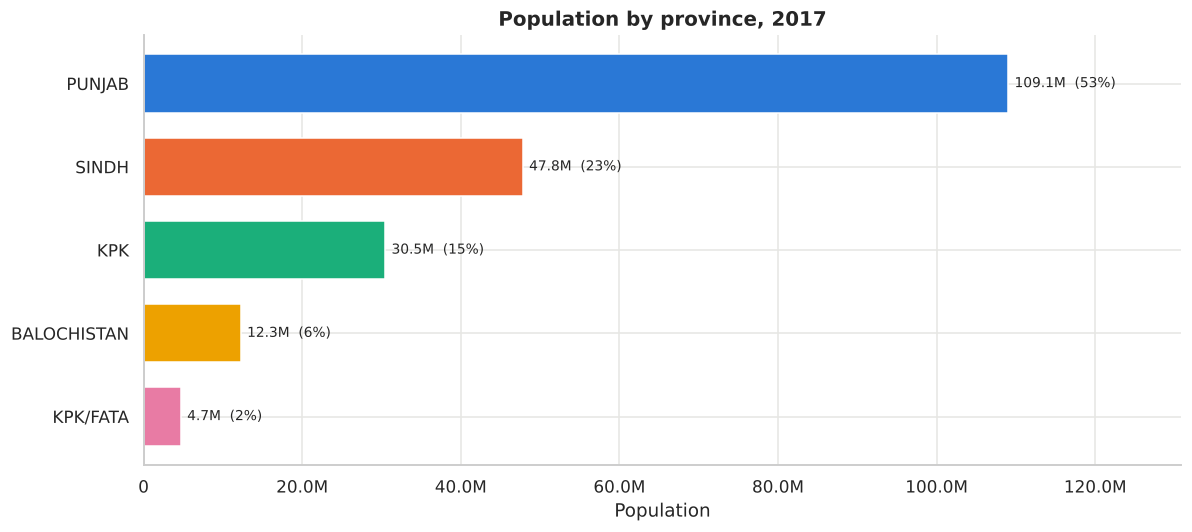

In [8]:
fig, ax = plt.subplots()
hbar(ax, prov.index, prov.POP_2017, [COLOR[p] for p in ORDER], [f"{v/1e6:.1f}M  ({s:.0%})" for v, s in zip(prov.POP_2017, prov.SHARE)])
ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(0, prov.POP_2017.max() * 1.2)
ax.set(title="Population by province, 2017", xlabel="Population", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- **Punjab has more than half of Pakistan (53%, 109M people)**. That is more people than most countries in the world.
- Sindh is second (23%) and KPK third (15%).
- **Balochistan has only 6% of the people**, even though it is the biggest province by land (see Plot 3).

### Plot 2 · Dumbbell chart: 1998 vs 2017, how much did each province grow?

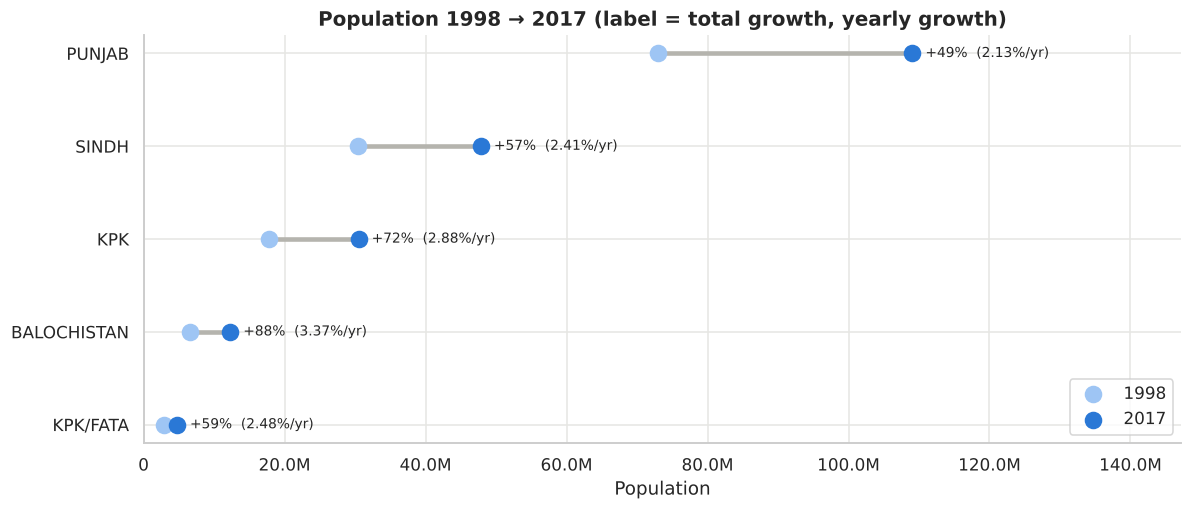

In [9]:
p = prov.sort_values("POP_2017")
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hlines(p.index, p.POP_1998, p.POP_2017, color="#b5b4ae", lw=3)
ax.scatter(p.POP_1998, p.index, s=110, color="#9ec5f4", label="1998", zorder=3)
ax.scatter(p.POP_2017, p.index, s=110, color=PALETTE[0], label="2017", zorder=3)
for prv, r in p.iterrows():
    ax.text(r.POP_2017, prv, f"   +{r.POP_2017/r.POP_1998-1:.0%}  ({r.CAGR:.2f}%/yr)", va="center", fontsize=9)
ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(0, p.POP_2017.max() * 1.35)
ax.set(title="Population 1998 → 2017 (label = total growth, yearly growth)", xlabel="Population")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation:** 
- Every province grew a lot, but **the smaller provinces grew faster**:
  - **Balochistan: +88% (3.37% per year)**, the fastest.
  - KPK: +72% (2.88%/yr).
  - **Punjab: +49% (2.13%/yr)**, the slowest, but because it is so big it still added the most people (**+36M**).
- The dumbbell chart is better than two bars side by side, because the **length of the grey line = growth**, so you can see it instantly.

### Plot 3 · Bar chart: Population density (people per sq. km), calculated correctly

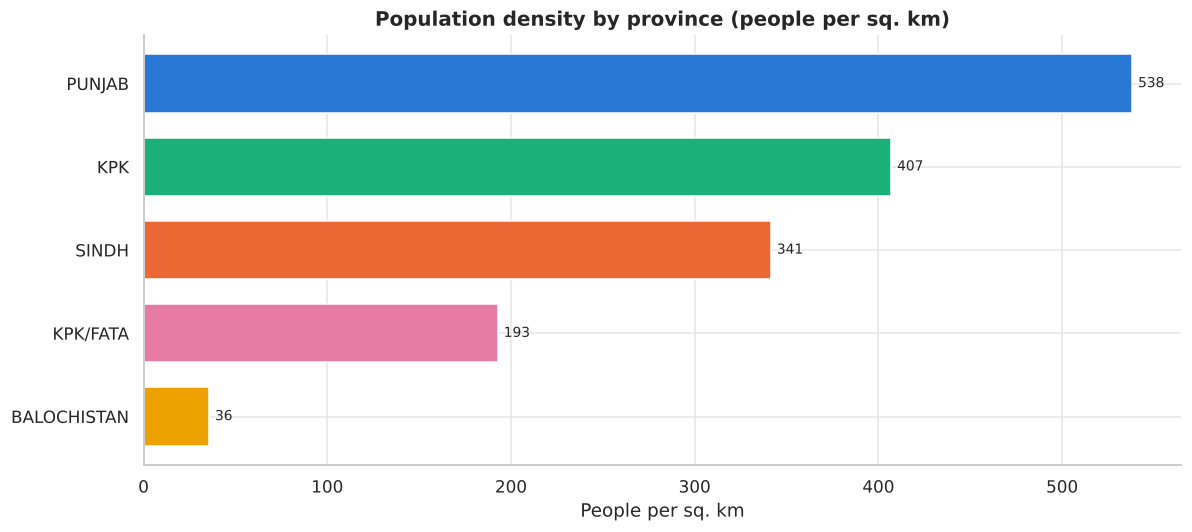

Pakistan average: 259 people/sq.km (4 Killa Saifullah tehsils with unknown area excluded)


In [10]:
dens = (prov.POP_2017 / prov.AREA).sort_values(ascending=False)
fig, ax = plt.subplots()
hbar(ax, dens.index, dens.values, [COLOR[p] for p in dens.index], [f"{v:.0f}" for v in dens.values])
ax.set(title="Population density by province (people per sq. km)", xlabel="People per sq. km", ylabel="")
plt.tight_layout(); plt.show()
print("Pakistan average:", round(df.POP_2017.sum() / df["AREA (SQ.KM)"].sum()), "people/sq.km",
      "(4 Killa Saifullah tehsils with unknown area excluded)")

**Interpretation:** 
- **Punjab is the most crowded: 538 people per sq. km.** KPK is second (407).
- **Balochistan has only 36 people per sq. km**, about 15 times emptier than Punjab. It is huge but mostly desert and mountains.
- The old notebook showed Killa Saifullah tehsils as the "most dense". That was wrong, caused by the AREA = 0 bug, and is now fixed.
- Pakistan average = **259 people per sq. km**.

---
## 6. Urban vs Rural (Q2)
### Plot 4 · 100% stacked bar: Urban and rural share in each province

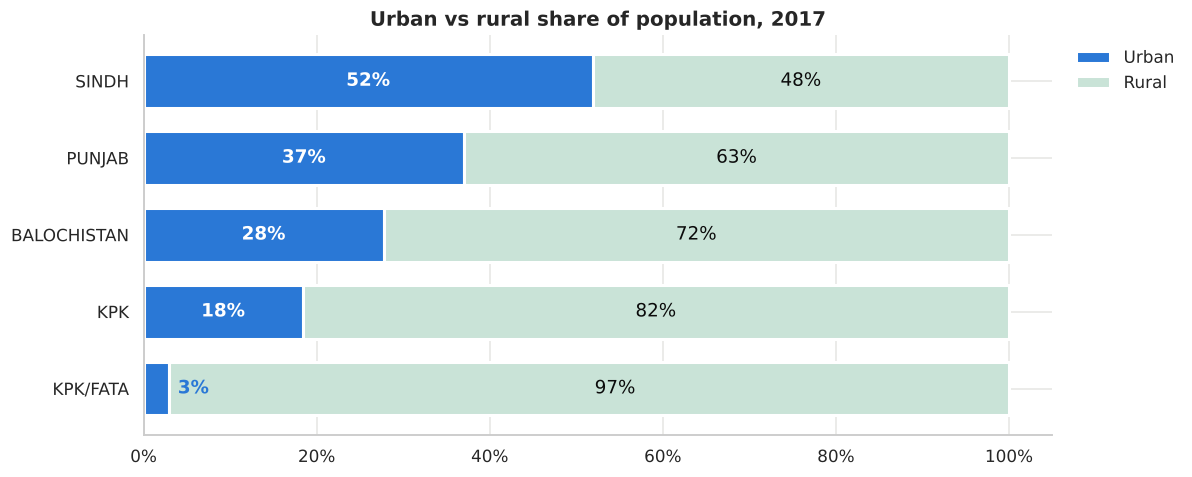

In [11]:
ur = pd.DataFrame({"Urban": prov.URBAN_2017 / prov.POP_2017, "Rural": prov.RURAL_2017 / prov.POP_2017})
ur = ur.sort_values("Urban")
ax = ur.plot.barh(stacked=True, color=[PALETTE[0], "#c9e3d7"], width=.7, edgecolor="white", linewidth=2, figsize=(11, 4.5))
for i, (u, r) in enumerate(ur.values):
    if u > .06: ax.text(u / 2, i, f"{u:.0%}", ha="center", va="center", color="white", fontweight="bold")
    else:       ax.text(u + .01, i, f"{u:.0%}", ha="left", va="center", color=PALETTE[0], fontweight="bold")
    ax.text(u + r / 2 + (.03 if u <= .06 else 0), i, f"{r:.0%}", ha="center", va="center", color="#0b0b0b")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Urban vs rural share of population, 2017", xlabel="", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); plt.tight_layout(); plt.show()

**Interpretation:** 
- **Sindh is the only province where most people (52%) live in cities**, thanks to Karachi and Hyderabad.
- Punjab is 37% urban, Balochistan 28%, KPK 18%.
- **FATA is almost completely rural (97%)**.
- So even after 70 years, Pakistan is still mostly a **village-based country** outside Sindh.

### Plot 5 · Slope chart: Urbanization 1998 → 2017

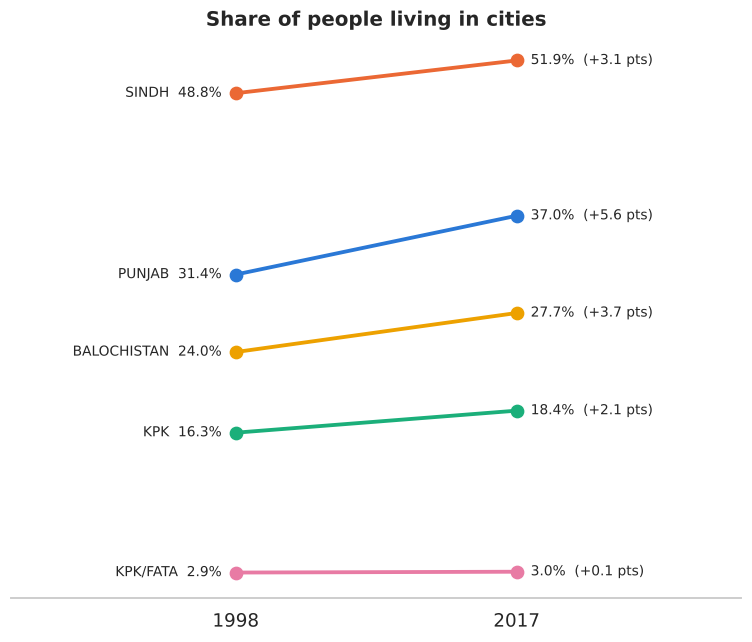

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for prv, r in prov.iterrows():
    ax.plot([0, 1], [r["URBAN_%_1998"], r["URBAN_%_2017"]], marker="o", lw=2.5, ms=8, color=COLOR[prv])
    ax.text(-0.05, r["URBAN_%_1998"], f"{prv}  {r['URBAN_%_1998']:.1f}%", ha="right", va="center", fontsize=9)
    ax.text(1.05, r["URBAN_%_2017"], f"{r['URBAN_%_2017']:.1f}%  ({r['URBAN_%_2017']-r['URBAN_%_1998']:+.1f} pts)", ha="left", va="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["1998", "2017"], fontsize=12); ax.set_xlim(-0.8, 1.8)
ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_title("Share of people living in cities")
plt.tight_layout(); plt.show()

**Interpretation:** 
- A slope chart shows "before vs after" for each province with one line. **A steeper line means faster urbanization.**
- **Punjab urbanized the most: +5.6 percentage points** (31.4% → 37.0%). Lahore, Faisalabad and Rawalpindi are pulling people in.
- Balochistan +3.7 and Sindh +3.1 points. KPK +2.1.
- **FATA did not change at all (+0.1)**.

### Plot 6 · Grouped bar: Are cities or villages growing faster? (yearly growth)

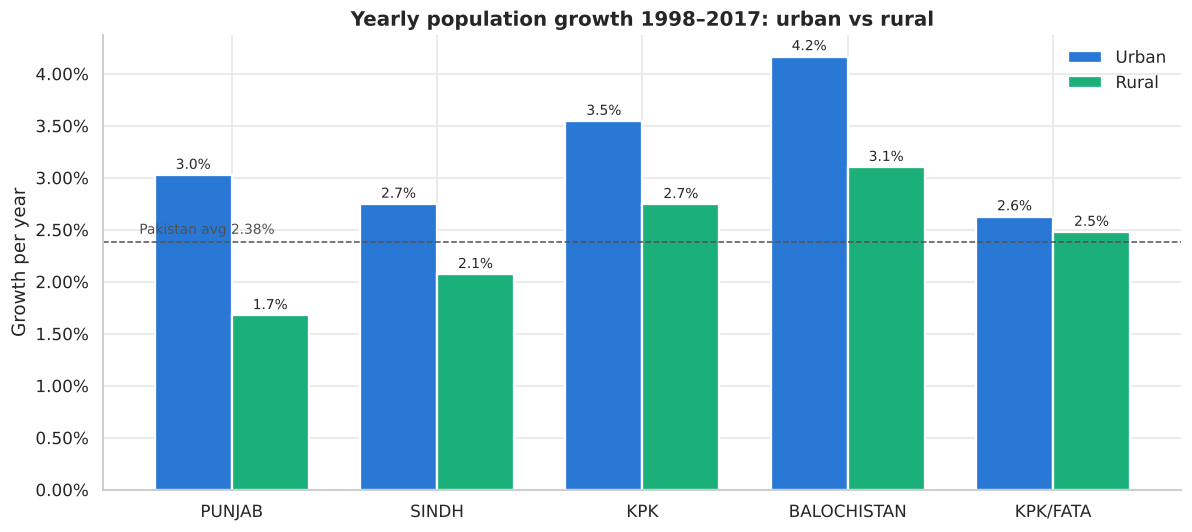

In [13]:
g = prov[["URBAN_CAGR", "RURAL_CAGR"]].rename(columns={"URBAN_CAGR": "Urban", "RURAL_CAGR": "Rural"})
ax = g.plot.bar(color=[PALETTE[0], PALETTE[2]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=9, padding=2)
ax.axhline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
ax.text(-0.45, cagr(P17, P98) + 0.08, f"Pakistan avg {cagr(P17, P98):.2f}%", ha="left", fontsize=9, color="#52514e")
ax.tick_params(axis="x", rotation=0); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Yearly population growth 1998–2017: urban vs rural", xlabel="", ylabel="Growth per year")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretation:** 
- **In every province, cities grew faster than villages.** People are moving from rural to urban areas.
- **Biggest gap is in Punjab: urban 3.0% vs rural 1.7% per year.** Villages in Punjab are growing slowly because people are moving to cities.
- **Balochistan cities grew 4.2% per year**, the fastest of all (Quetta).
- In FATA, urban and rural growth are almost the same (2.6% vs 2.5%), so there is no real migration to cities there.
- Dashed line = Pakistan average (2.38%).

---
## 7. How is population spread? (Q3, Q5)
### Plot 7 · Histogram (log scale): Size of tehsils

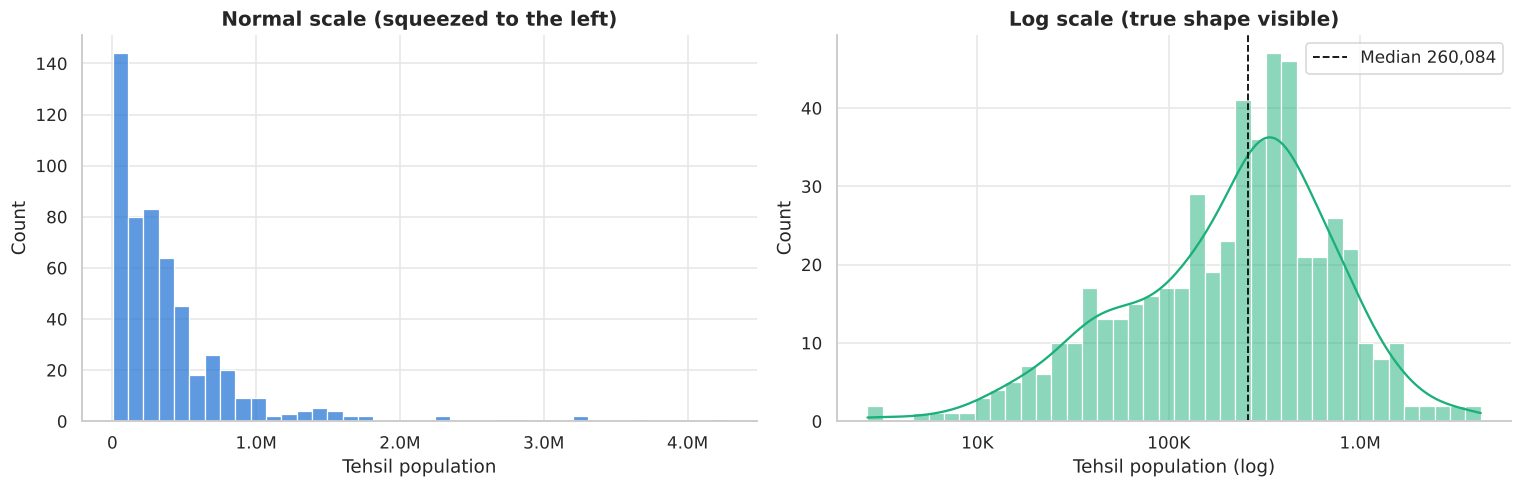

count          528
mean       387,142
std        477,957
min          2,665
25%         98,452
50%        260,084
75%        460,310
90%        846,193
max      4,267,198


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.histplot(df.POP_2017, bins=40, color=PALETTE[0], ax=axes[0])
axes[0].xaxis.set_major_formatter(HUMAN); axes[0].set(title="Normal scale (squeezed to the left)", xlabel="Tehsil population")
sns.histplot(df.POP_2017, bins=40, log_scale=True, kde=True, color=PALETTE[2], ax=axes[1])
axes[1].axvline(df.POP_2017.median(), color="#0b0b0b", ls="--", lw=1.2, label=f"Median {df.POP_2017.median():,.0f}")
axes[1].xaxis.set_major_formatter(HUMAN); axes[1].set(title="Log scale (true shape visible)", xlabel="Tehsil population (log)")
axes[1].legend(); plt.tight_layout(); plt.show()
print(df.POP_2017.describe(percentiles=[.25, .5, .75, .9]).apply(lambda v: f"{v:,.0f}").to_string())

**Interpretation:** 
- On the normal scale almost all tehsils are bunched on the left, because a few giant tehsils stretch the axis. **The data is right-skewed.**
- On the **log scale** we can see the real shape: most tehsils have between **100K and 500K** people.
- **Median tehsil = 260,084 people** (half are smaller, half bigger). The mean (387K) is higher because of the giants, so **use the median** here.

### Plot 8 · Box plot: Tehsil sizes in each province

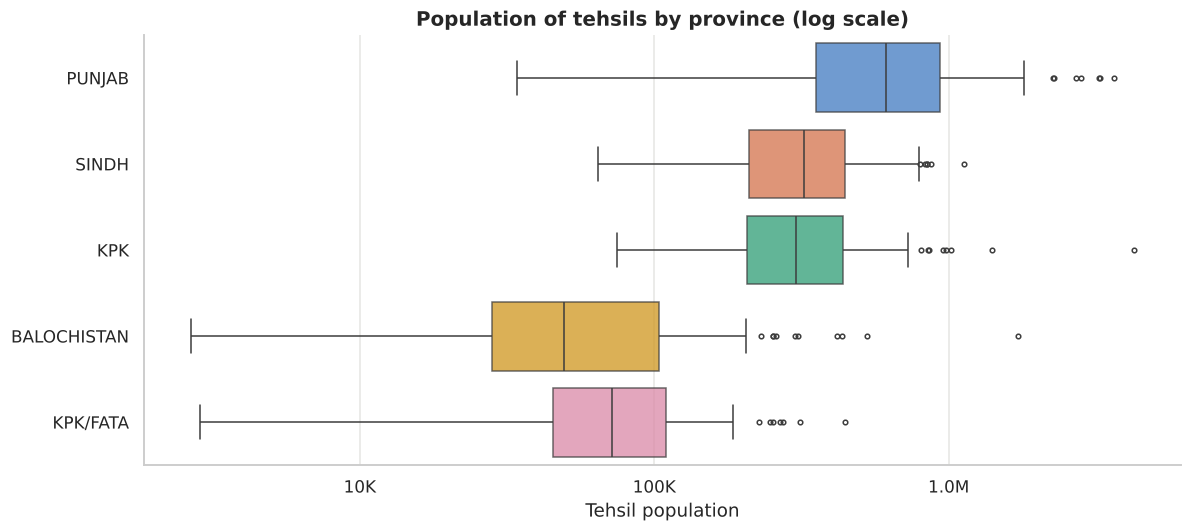

PROVINCE
PUNJAB         613,305
SINDH          322,376
KPK            303,644
BALOCHISTAN     49,480
KPK/FATA        71,754


In [15]:
plt.figure(figsize=(11, 5))
ax = sns.boxplot(data=df, x="POP_2017", y="PROVINCE", order=ORDER, palette=COLOR, fliersize=3, boxprops=dict(alpha=.75))
ax.set_xscale("log"); ax.xaxis.set_major_formatter(HUMAN)
ax.set(title="Population of tehsils by province (log scale)", xlabel="Tehsil population", ylabel="")
plt.tight_layout(); plt.show()
print(df.groupby("PROVINCE")["POP_2017"].median().reindex(ORDER).apply(lambda v: f"{v:,.0f}").to_string())

**Interpretation:** 
- **Punjab tehsils are the biggest** (median about 613K people each).
- **Balochistan tehsils are tiny** (median about 49K), roughly 12 times smaller than Punjab's. Balochistan is split into many small tehsils across a huge area.
- KPK has one extreme outlier dot on the right: **Peshawar tehsil (4.27M)**, the largest tehsil in the dataset.

In [16]:
# District-level table used by the next plots
dist = df.groupby(["PROVINCE", "DISTRICT"]).agg(POP_2017=("POP_2017", "sum"), POP_1998=("POP_1998", "sum"),
                                                URBAN_2017=("URBAN_2017", "sum"), AREA=("AREA (SQ.KM)", lambda s: s.sum(min_count=len(s))),
                                                MALE=("MALE", "sum"), FEMALE=("FEMALE", "sum"),
                                                HH=("HH_RURAL", "sum"), HH_U=("HH_URBAN", "sum")).reset_index()
dist["NAME"] = dist.DISTRICT.str.replace(" DISTRICT", "").str.title()
dist["CAGR"] = cagr(dist.POP_2017, dist.POP_1998)
dist["URBAN_%"] = dist.URBAN_2017 / dist.POP_2017 * 100
dist["DENSITY"] = dist.POP_2017 / dist.AREA          # NaN where area is unknown
dist["SEX_RATIO"] = dist.MALE / dist.FEMALE * 100
dist["HH_SIZE"] = dist.POP_2017 / (dist.HH + dist.HH_U)
print("Districts:", len(dist))

Districts: 131


### Plot 9 · Horizontal bar: 15 biggest districts

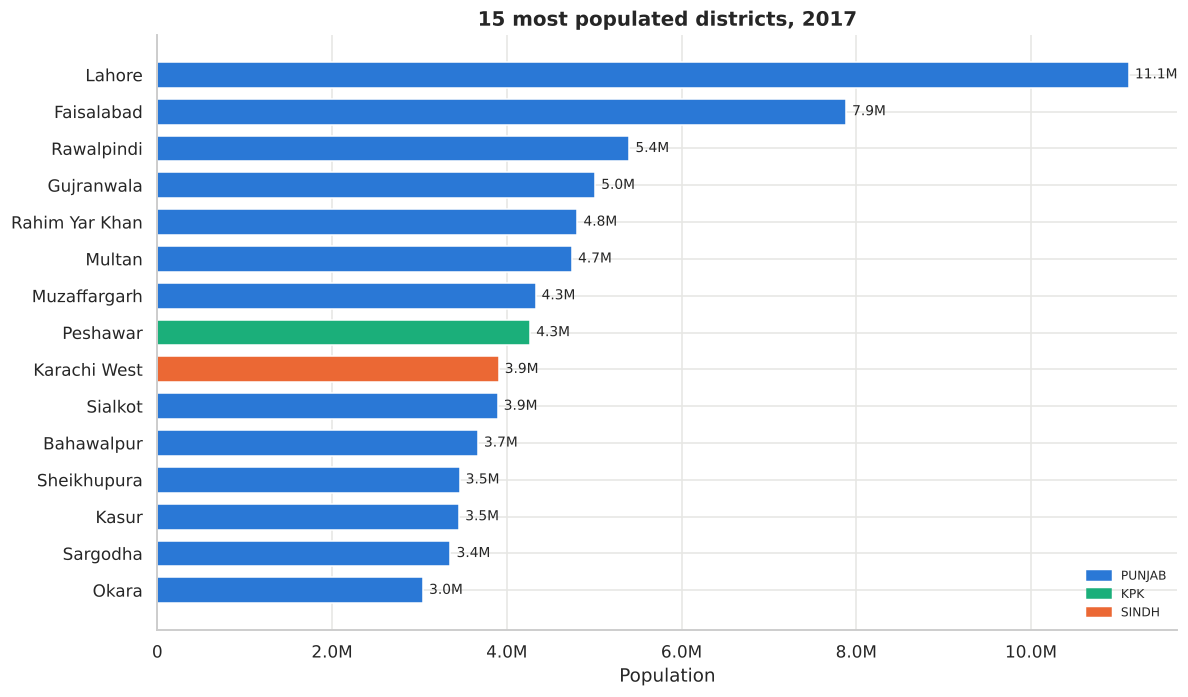

In [17]:
top = dist.nlargest(15, "POP_2017")
fig, ax = plt.subplots(figsize=(11, 6.5))
hbar(ax, top.NAME, top.POP_2017, top.PROVINCE.map(COLOR), [f"{v/1e6:.1f}M" for v in top.POP_2017], legend=top.PROVINCE.unique())
ax.xaxis.set_major_formatter(HUMAN)
ax.set(title="15 most populated districts, 2017", xlabel="Population", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- **Lahore is the biggest district by far (11.1M)**, then Faisalabad (7.9M) and Rawalpindi (5.4M).
- **12 of the top 15 districts are in Punjab.** Only Peshawar (KPK) and Karachi West (Sindh) break in.
- ⚠️ Karachi does not look big here because **Karachi is split into 6 districts** in this data. Added together, Karachi Division has **16.0M people**, more than Lahore.

### Plot 10 · Bar chart: Most crowded districts (density, area = 0 problem fixed)

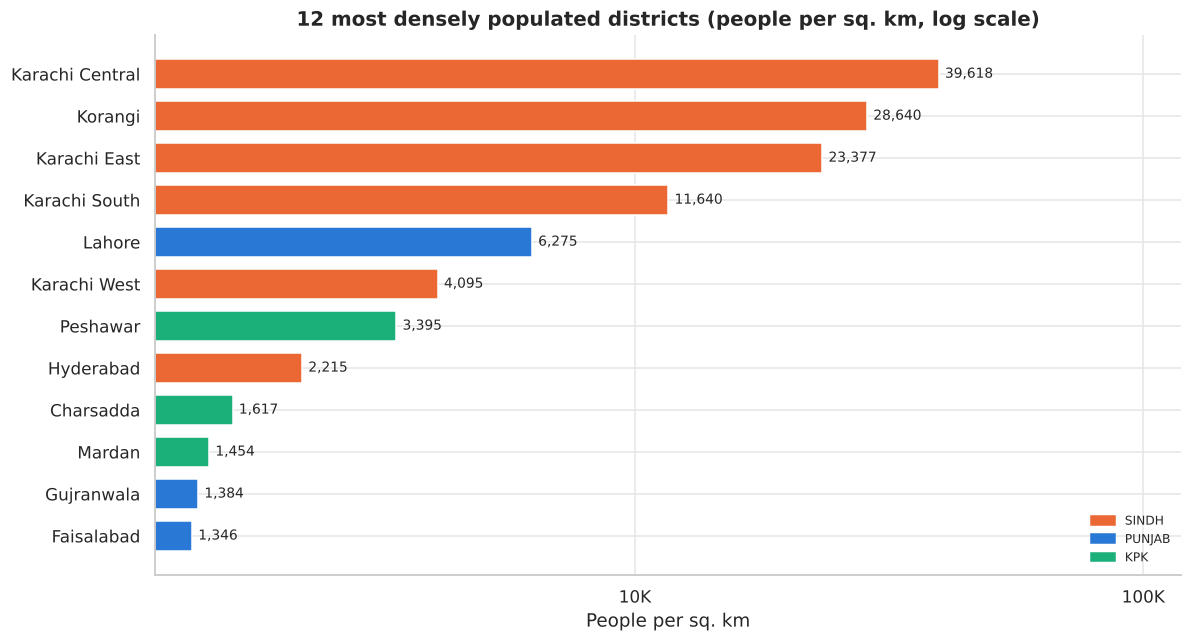

In [18]:
d = dist.dropna(subset=["DENSITY"]).nlargest(12, "DENSITY")
fig, ax = plt.subplots(figsize=(11, 6))
hbar(ax, d.NAME, d.DENSITY, d.PROVINCE.map(COLOR), [f"{v:,.0f}" for v in d.DENSITY], legend=d.PROVINCE.unique())
ax.set_xscale("log"); ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(right=d.DENSITY.max() * 3)
ax.set(title="12 most densely populated districts (people per sq. km, log scale)", xlabel="People per sq. km", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- **Karachi Central is the most crowded place: about 39,600 people per sq. km!** Korangi and Karachi East are next.
- **The top 4 are all Karachi districts.** Lahore is 5th (about 6,300).
- A log scale is used because Karachi Central is about 30 times denser than Faisalabad.
- Such high density means heavy pressure on **water, transport, schools and hospitals**.

### Plot 11 · Bar chart: Fastest and slowest growing districts

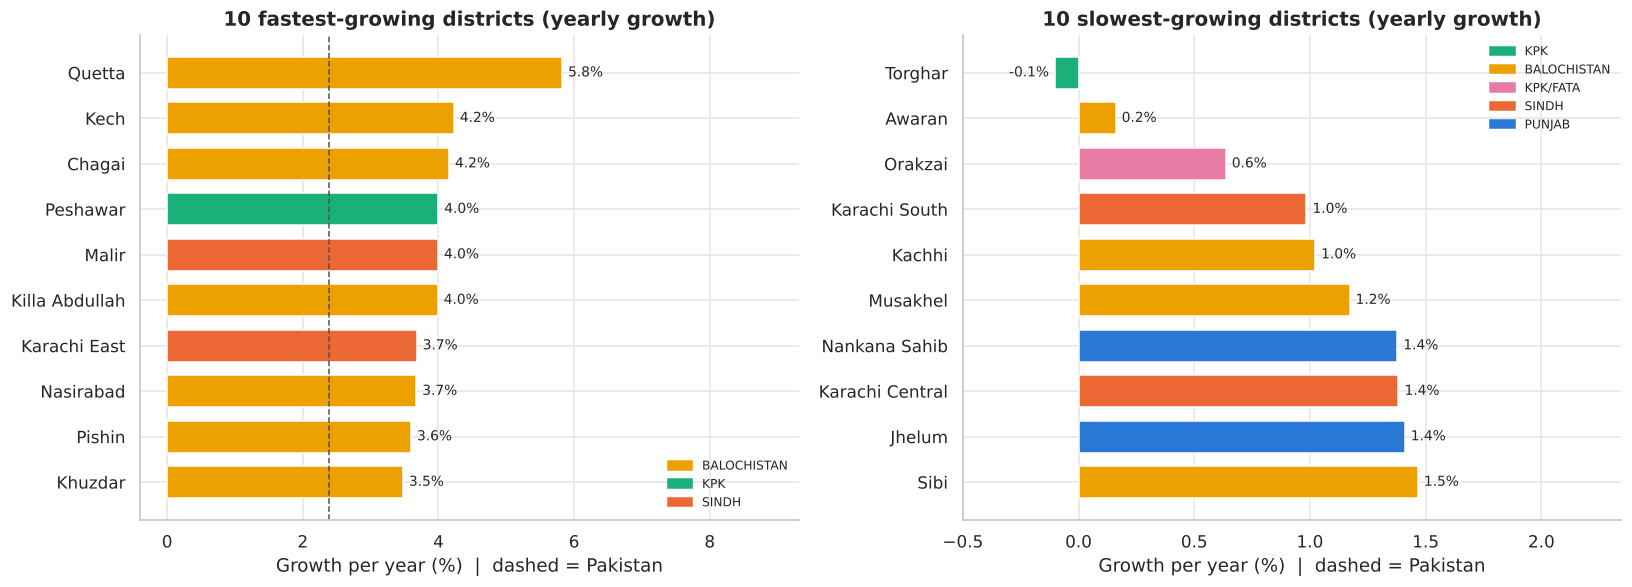

In [19]:
big = dist[dist.POP_1998 >= 100_000]                 # ignore very small districts (unstable %)
fast, slow = big.nlargest(10, "CAGR"), big.nsmallest(10, "CAGR")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, data, title, loc in [(axes[0], fast, "10 fastest-growing districts", "lower right"), (axes[1], slow, "10 slowest-growing districts", "upper right")]:
    hbar(ax, data.NAME, data.CAGR, data.PROVINCE.map(COLOR), [f"{v:.1f}%" for v in data.CAGR], legend=data.PROVINCE.unique(), loc=loc)
    ax.axvline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
    ax.set_xlim(min(0, data.CAGR.min()) - 0.4, data.CAGR.max() * 1.6)
    ax.set(title=title + " (yearly growth)", xlabel="Growth per year (%)  |  dashed = Pakistan", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:** 
- **Fastest: Quetta (5.8% per year)**, so its population tripled in 19 years. **7 of the top 10 fastest are in Balochistan.** Peshawar and Malir (Karachi) also grew fast.
- **Slowest:** Torghar actually *shrank* (−0.1%), and Awaran barely grew (0.2%). Interesting: **old Karachi centres (South 1.0%, Central 1.4%) grew slowly**, because they are already full and new people settle in outer areas like Malir.
- Small districts (under 100K in 1998) are excluded, because a small base gives misleading percentages.

### Plot 12 · Pareto curve: Do a few districts hold most of the people?

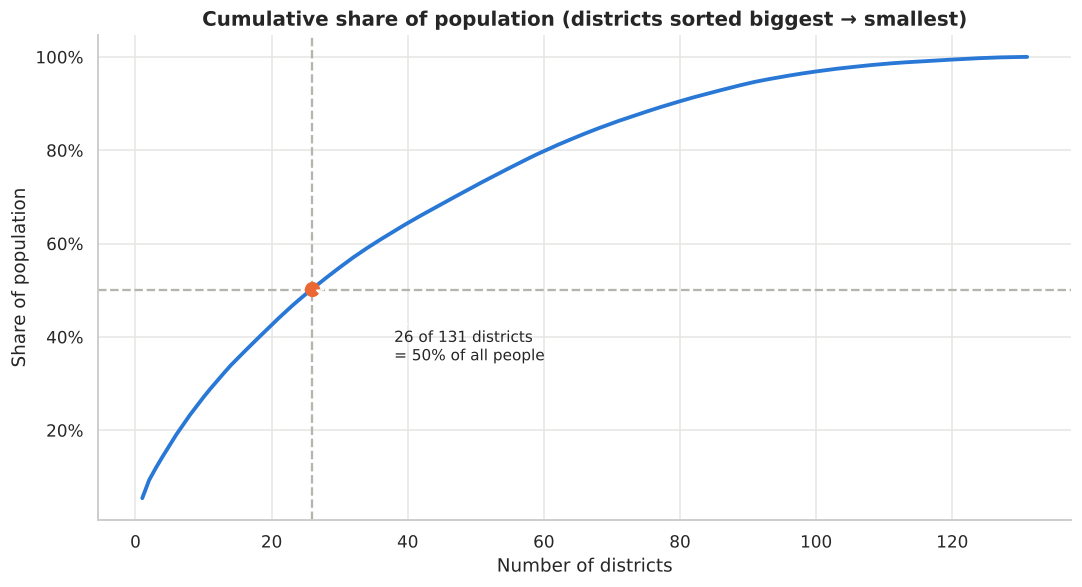

Top 10 districts hold 27% of the population


In [20]:
s = dist.POP_2017.sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
n50 = int((cum < .5).sum() + 1)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(np.arange(1, len(s) + 1), cum, color=PALETTE[0], lw=2.5)
ax.axhline(.5, color="#b5b4ae", ls="--"); ax.axvline(n50, color="#b5b4ae", ls="--")
ax.scatter([n50], [cum[n50 - 1]], s=80, color=PALETTE[1], zorder=3)
ax.annotate(f"{n50} of {len(s)} districts\n= 50% of all people", (n50, cum[n50 - 1]), xytext=(n50 + 12, .35),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Cumulative share of population (districts sorted biggest → smallest)", xlabel="Number of districts", ylabel="Share of population")
plt.tight_layout(); plt.show()
print(f"Top 10 districts hold {cum[9]:.0%} of the population")

**Interpretation:** 
- If population were spread evenly, the line would be straight. It bends upward, so population is **concentrated**.
- **Just 26 of 131 districts (20%) hold half of all Pakistanis.**
- The top 10 districts alone hold **27%** of the population.
- **Meaning for planning:** a few big districts need the most services, but the many small districts must not be forgotten.

### Plot 13 · Bubble scatter: Do more urban districts grow faster?

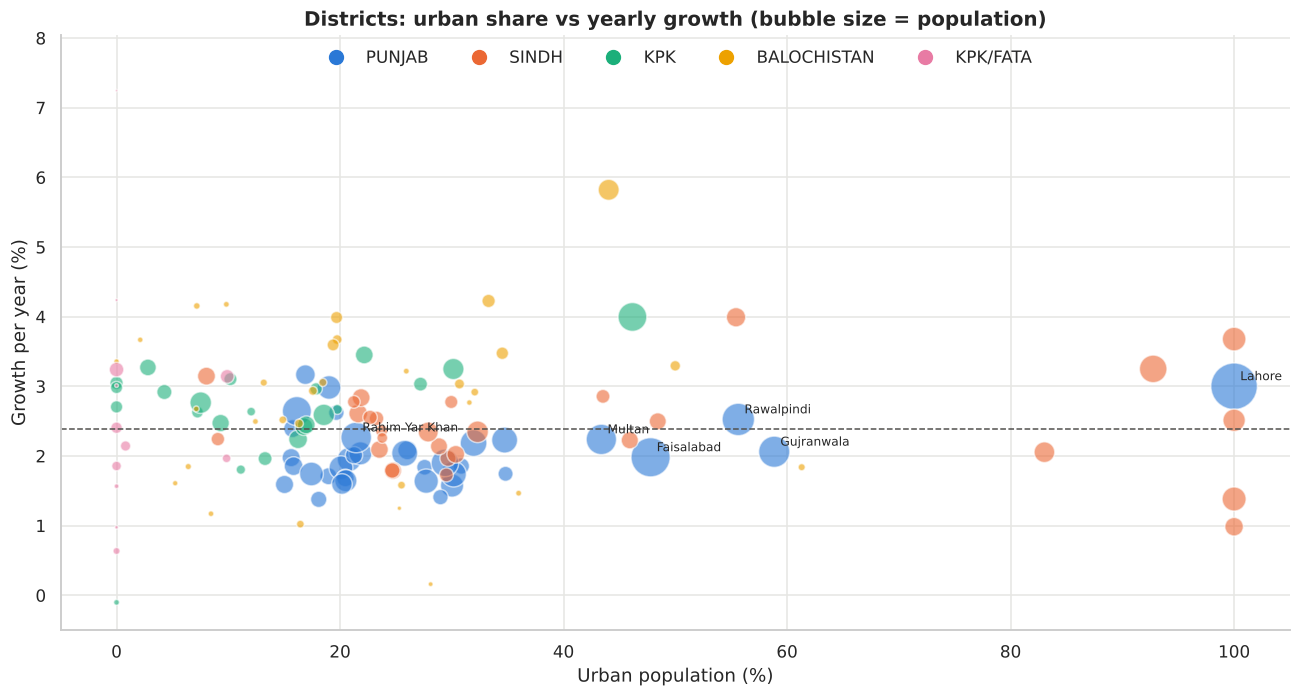

Spearman correlation (urban % vs growth): -0.07


In [21]:
fig, ax = plt.subplots(figsize=(12, 6.5))
for prv in ORDER:
    sub = dist[dist.PROVINCE == prv]
    ax.scatter(sub["URBAN_%"], sub.CAGR, s=sub.POP_2017 / 12_000, color=COLOR[prv], alpha=.6, edgecolor="white", label=prv)
for _, r in dist.nlargest(6, "POP_2017").iterrows():
    ax.annotate(r.NAME, (r["URBAN_%"], r.CAGR), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=COLOR[p], label=p) for p in ORDER], frameon=False, loc="upper center", ncol=5)
ax.set_ylim(dist.CAGR.min() - .4, dist.CAGR.max() + .8)
ax.set(title="Districts: urban share vs yearly growth (bubble size = population)", xlabel="Urban population (%)", ylabel="Growth per year (%)")
plt.tight_layout(); plt.show()
print("Spearman correlation (urban % vs growth):", round(dist["URBAN_%"].corr(dist.CAGR, method="spearman"), 2))

**Interpretation:** 
- Each bubble is a district. **Right = more urban, Up = faster growth, Bigger = more people.**
- The dots are scattered with **no clear pattern (correlation −0.07)**. Being more urban does *not* by itself make a district grow faster.
- Fast growth (top area) comes mostly from **Balochistan (yellow) districts of every type**, while big Punjab cities (Lahore, Faisalabad, Gujranwala) sit near the average line.
- Lesson: always check with a chart before assuming a relationship.

---
## 8. Gender & Households (Q4)
### Plot 14 · Grouped bar: Sex ratio (rural vs urban), calculated correctly

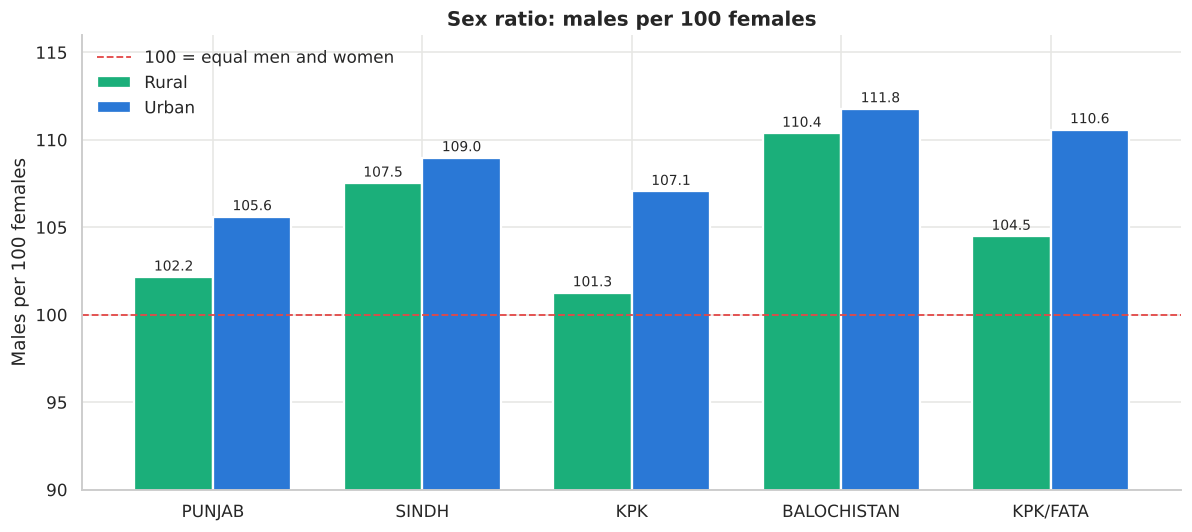

❌ Old wrong method (simple mean, zeros included): {'BALOCHISTAN': 47.6, 'KPK': 59.5, 'KPK/FATA': 15.6, 'PUNJAB': 101.5, 'SINDH': 103.1}
✅ Correct urban sex ratio: {'PUNJAB': 105.6, 'SINDH': 109.0, 'KPK': 107.1, 'BALOCHISTAN': 111.8, 'KPK/FATA': 110.6}


In [22]:
g = df.groupby("PROVINCE")[["MALE (RURAL)", "FEMALE (RURAL)", "MALE (URBAN)", "FEMALE (URBAN)"]].sum()
sr = pd.DataFrame({"Rural": g["MALE (RURAL)"] / g["FEMALE (RURAL)"] * 100,
                   "Urban": g["MALE (URBAN)"] / g["FEMALE (URBAN)"] * 100}).reindex(ORDER)
ax = sr.plot.bar(color=[PALETTE[2], PALETTE[0]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=9, padding=2)
ax.axhline(100, color="#e34948", ls="--", lw=1.2, label="100 = equal men and women")
ax.set_ylim(90, 116); ax.tick_params(axis="x", rotation=0)
ax.set(title="Sex ratio: males per 100 females", xlabel="", ylabel="Males per 100 females")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
raw = pd.read_csv("Population-Dataset.csv")
print("❌ Old wrong method (simple mean, zeros included):", raw.groupby("PROVINCE")["SEX RATIO (URBAN)"].mean().round(1).to_dict())
print("✅ Correct urban sex ratio:", sr.Urban.round(1).to_dict())

**Interpretation:** 
- **All values are above 100, so there are more men than women everywhere.**
- **Cities have more men than villages** in every province. Men move to cities for work and often leave their families in the village.
- **Balochistan has the highest ratio (111.8 urban)**, and FATA cities are 110.6.
- 🔧 **Fix shown:** the old method (simple average with zeros) gave Balochistan urban **47.6** and FATA **15.6**, which would mean twice as many women as men. That was totally wrong. The correct values are 111.8 and 110.6.

### Plot 15 · Grouped bar: Average household size (rural vs urban)

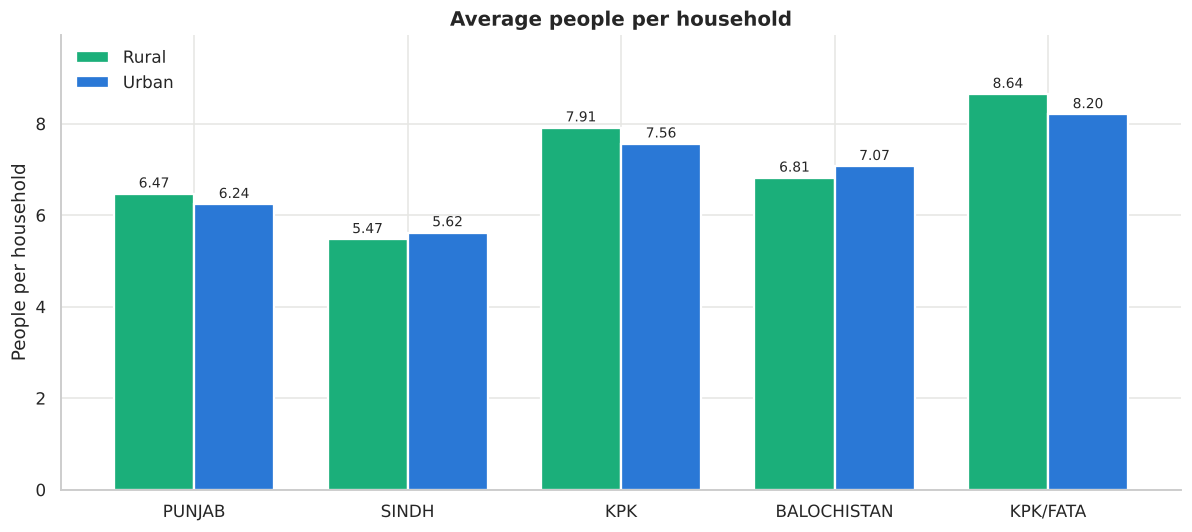

Pakistan: 6.4 people per household


In [23]:
h = df.groupby("PROVINCE").agg(R=("ALL SEXES (RURAL)", "sum"), HR=("HH_RURAL", "sum"), U=("ALL SEXES (URBAN)", "sum"), HU=("HH_URBAN", "sum"))
hh = pd.DataFrame({"Rural": h.R / h.HR, "Urban": h.U / h.HU}).reindex(ORDER)
ax = hh.plot.bar(color=[PALETTE[2], PALETTE[0]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, hh.max().max() * 1.15); ax.tick_params(axis="x", rotation=0)
ax.set(title="Average people per household", xlabel="", ylabel="People per household")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("Pakistan:", round(df.POP_2017.sum() / (df.HH_RURAL.sum() + df.HH_URBAN.sum()), 2), "people per household")

**Interpretation:** 
- **Average Pakistani household = 6.4 people.**
- **FATA (8.6) and KPK (7.9) have the biggest households**, because joint family systems are common there.
- **Sindh has the smallest (about 5.5).**
- In Punjab and KPK, urban homes are a bit smaller than rural ones. In Sindh and Balochistan, urban homes are slightly bigger.

### Plot 16 · Bar chart: Transgender population counted

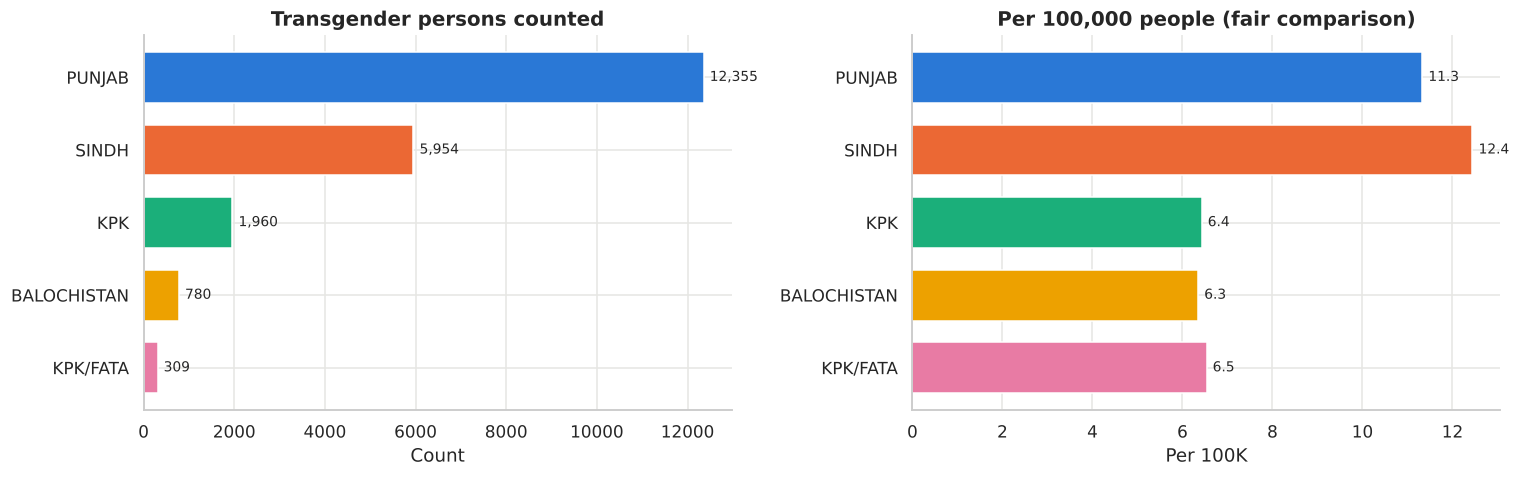

Living in urban areas: 55% of transgender persons vs 36% of all people


In [24]:
t = df.groupby("PROVINCE").agg(TG=("TRANSGENDER", "sum"), POP=("POP_2017", "sum")).reindex(ORDER)
t["PER_100K"] = t.TG / t.POP * 1e5
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hbar(axes[0], t.index, t.TG, [COLOR[p] for p in t.index], [f"{v:,.0f}" for v in t.TG])
axes[0].set(title="Transgender persons counted", xlabel="Count", ylabel="")
hbar(axes[1], t.index, t.PER_100K, [COLOR[p] for p in t.index], [f"{v:.1f}" for v in t.PER_100K])
axes[1].set(title="Per 100,000 people (fair comparison)", xlabel="Per 100K", ylabel="")
plt.tight_layout(); plt.show()
urb_tg = (df["TRANSGENDER (URBAN)"].sum() / df.TRANSGENDER.sum())
print(f"Living in urban areas: {urb_tg:.0%} of transgender persons vs {df.URBAN_2017.sum()/P17:.0%} of all people")

**Interpretation:** 
- In total **21,358 transgender persons** were counted. 2017 was the first time the census counted them.
- Punjab has the biggest *count* (12,355), but **per 100,000 people Sindh is highest (12.4)**, then Punjab (11.3).
- Raw counts can mislead, which is why the right-hand chart **compares fairly per 100K people**.
- **55% live in cities, compared with 36% of the general population.** Many move to cities for community and jobs.
- Many experts believe the real number is higher, because of under-reporting.

### Plot 17 · Correlation heatmap (district level, clean data)

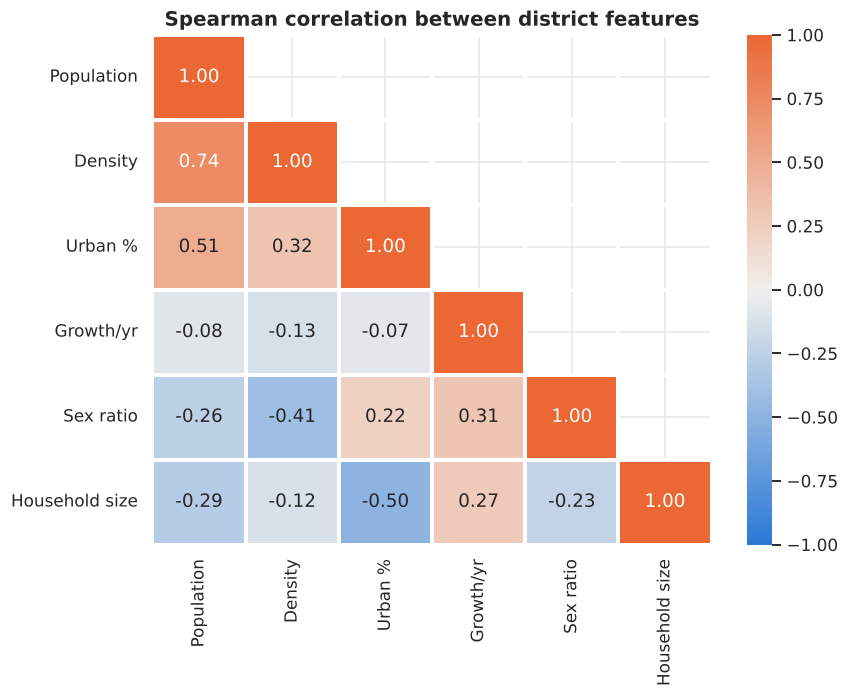

In [25]:
cols = {"POP_2017": "Population", "DENSITY": "Density", "URBAN_%": "Urban %", "CAGR": "Growth/yr",
        "SEX_RATIO": "Sex ratio", "HH_SIZE": "Household size"}
corr = dist[list(cols)].rename(columns=cols).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, linewidths=1.5, linecolor="white",
            cmap=sns.blend_palette(["#2a78d6", "#f0efec", "#eb6834"], as_cmap=True))
plt.title("Spearman correlation between district features"); plt.tight_layout(); plt.show()

**Interpretation:** 
How to read it: **orange = both go up together, blue = one goes up while the other goes down**, and near 0 = no relation.
- **Population ↔ Density (0.74):** big districts are also crowded.
- **Urban % ↔ Household size (−0.50):** **more urban districts have smaller families.**
- **Density ↔ Sex ratio (−0.41):** crowded districts have a more balanced men/women ratio.
- **Growth ↔ Urban % (−0.07):** no relation, confirming Plot 13.
- ⚠️ Correlation does not prove cause and effect.

> Why **Spearman** and not Pearson? Population data is very skewed (a few huge districts like Lahore and Karachi). Spearman works on ranks, so a few giants cannot distort the result.

---
## 9. 📋 Final Summary

### 9.1 Key findings (simple answers)

| # | Question | Answer |
|---|---|---|
| Q1 | Size & growth | **204.4M people** (without Islamabad), up from 130.7M in 1998 (**+56%, 2.38%/year**). **Punjab = 53%** of the people. **Balochistan grew fastest (3.37%/yr)**, Punjab slowest (2.13%/yr). |
| Q2 | Urban vs rural | Only **36% urban** (up from 32%). **Sindh is the only urban-majority province (52%).** Cities grow faster than villages everywhere, most of all in **Punjab (3.0% vs 1.7%)**. |
| Q3 | Biggest / crowded / fastest | Biggest district: **Lahore (11.1M)**. Most crowded: **Karachi Central (about 39,600/sq.km)**. Fastest growing: **Quetta (5.8%/yr)**. |
| Q4 | Gender & households | **104.8 men per 100 women**, with more men in cities (work migration). Average household **6.4 people**, largest in **FATA/KPK**. **21,358 transgender persons**, 55% in cities. |
| Q5 | Concentration | **26 of 131 districts hold half the population.** |

### 9.2 Recommendations
1. **Plan for fast-growing cities:** Quetta, Peshawar and Karachi's outer districts (Malir, Karachi East) need housing, water and transport first.
2. **Balochistan and KPK** have the highest growth and biggest families. Focus on **family planning, schools and health** there.
3. **Karachi's density** (up to about 40K/sq.km) needs urgent investment in public transport and water.
4. **Do not forget rural Pakistan:** 64% of people live in villages, so rural jobs can reduce pressure on cities.

### 9.3 What was fixed compared with the first version
| Problem | Fix |
|---|---|
| AREA = 0 → density = infinity | Set to NaN; Karachi now correctly shows as most crowded |
| Zeros averaged into urban sex ratio and household size (e.g. FATA urban 15.6) | Calculated from totals → 110.6 |
| Simple `.mean()` of rates across tehsils | Totals first, then ratio (weighted) |
| Total growth only (+88%) | Added yearly growth (CAGR) |
| Wrong sex ratio definition | Males per 100 females |
| Mixed-case names, FATA separate | Upper-cased, added `PROVINCE_2018` |
| Charts without labels, 1e8 axes | Labels, M/K format, same colour per province |
| No explanations | Interpretation under every chart + summary |

### 9.4 Limitations & next steps
- Islamabad is not in this file, and Killa Saifullah's area is unknown.
- **Next steps:** add the **2023 census** to compare 3 points in time, draw a **district map** (geopandas/plotly), and join with literacy or income data to explain *why* some areas grow faster.